<a href="https://colab.research.google.com/github/Devinder265/React-Projects/blob/main/Copy_of_Untitled13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries successfully imported!")

Libraries successfully imported!


Section 2: Load and Explore Datasets

In [ ]:
titles_df = pd.read_csv('/content/titles.csv.zip')
credits_df = pd.read_csv('/content/credits.csv.zip')

print("--- TITLES DATASET ---")
print(f"Shape: {titles_df.shape}")
display(titles_df.head(2))
print(titles_df.info())

print("\n--- CREDITS DATASET ---")
print(f"Shape: {credits_df.shape}")
display(credits_df.head(2))
print(credits_df.info())

--- TITLES DATASET ---
Shape: (9871, 15)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(

,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124235 entries, 0 to 124234
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   person_id  124235 non-null  int64 
 1   id         124235 non-null  object
 2   name       124235 non-null  object
 3   character  107948 non-null  object
 4   role       124235 non-null  object
dtypes: int64(1), object(4)
memory usage: 4.7+ MB
None


Merge Datasets

In [ ]:
# Left merge to preserve all records from titles
merged_df = pd.merge(titles_df, credits_df, on='id', how='left')

# Create a unique dataframe for title-level statistics
unique_titles = titles_df.copy()

print(f"Merged DataFrame Shape: {merged_df.shape}")
print(f"Unique Titles Shape: {unique_titles.shape}")

# Explanation of duplication
print("\nNote: Merging titles and credits expands rows because one title can have multiple crew/cast members associated with it via the 'id' column.")

Merged DataFrame Shape: (125354, 19)
Unique Titles Shape: (9871, 15)

Note: Merging titles and credits expands rows because one title can have multiple crew/cast members associated with it via the 'id' column.


Data Cleaning and Missing Value Profiling

,Missing Count,Missing Percentage
id,0,0.000000
title,0,0.000000
type,0,0.000000
description,119,1.205552
release_year,0,0.000000
age_certification,6487,65.717759
runtime,0,0.000000
genres,0,0.000000
production_countries,0,0.000000
seasons,8514,86.252659


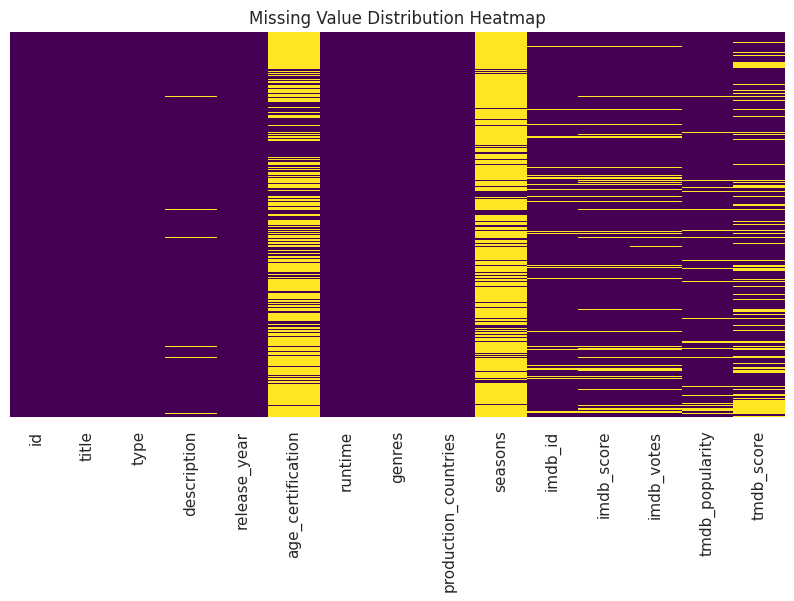

In [ ]:
# Missing values profiling for Unique Titles
missing_stats = unique_titles.isnull().sum().to_frame(name='Missing Count')
missing_stats['Missing Percentage'] = (missing_stats['Missing Count'] / len(unique_titles)) * 100
display(missing_stats)

# Heatmap visualization
plt.figure(figsize=(10, 5))
sns.heatmap(unique_titles.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Value Distribution Heatmap')
plt.show()

In [ ]:
# Clean Categorical Values
unique_titles['age_certification'] = unique_titles['age_certification'].fillna('Unknown')
unique_titles['genres'] = unique_titles['genres'].fillna('[]')
unique_titles['production_countries'] = unique_titles['production_countries'].fillna('[]')
unique_titles['description'] = unique_titles['description'].fillna('No Description Available')

merged_df['name'] = merged_df['name'].fillna('Unknown')
merged_df['character'] = merged_df['character'].fillna('Unknown')
merged_df['role'] = merged_df['role'].fillna('Unknown')

# Handle missing values for seasons based on type
unique_titles.loc[unique_titles['type'] == 'MOVIE', 'seasons'] = 0
show_season_median = unique_titles[unique_titles['type'] == 'SHOW']['seasons'].median()
unique_titles.loc[unique_titles['type'] == 'SHOW', 'seasons'] = unique_titles.loc[unique_titles['type'] == 'SHOW', 'seasons'].fillna(show_season_median)

# Check numerical imputation targets
print("Missing values handled for categorical features and seasons!")

Missing values handled for categorical features and seasons!


Exploratory Data Analysis & Visualizations

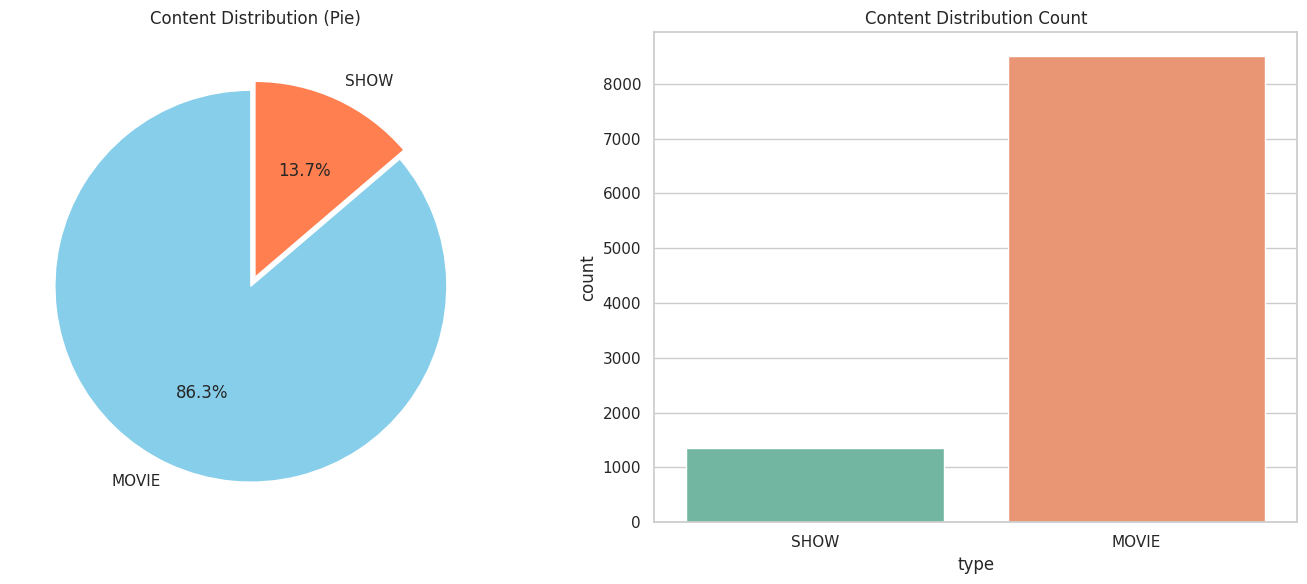

In [ ]:
# Vis 1: Movies vs TV Shows
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
type_counts = unique_titles['type'].value_counts()
type_counts.plot.pie(autopct='%1.1f%%', ax=axes[0], colors=['skyblue', 'coral'], startangle=90, explode=(0.05, 0))
axes[0].set_ylabel('')
axes[0].set_title('Content Distribution (Pie)')

sns.countplot(data=unique_titles, x='type', ax=axes[1], palette='Set2')
axes[1].set_title('Content Distribution Count')
plt.tight_layout()
plt.show()

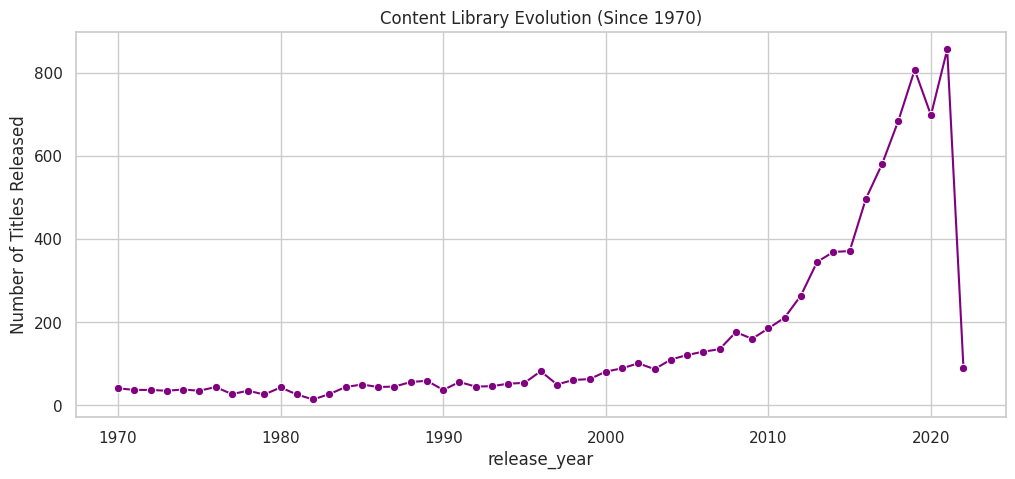

In [ ]:
# Vis 2: Content Release Trends
release_trends = unique_titles.groupby('release_year')['id'].count().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=release_trends[release_trends['release_year'] >= 1970], x='release_year', y='id', marker='o', color='purple')
plt.title('Content Library Evolution (Since 1970)')
plt.ylabel('Number of Titles Released')
plt.show()

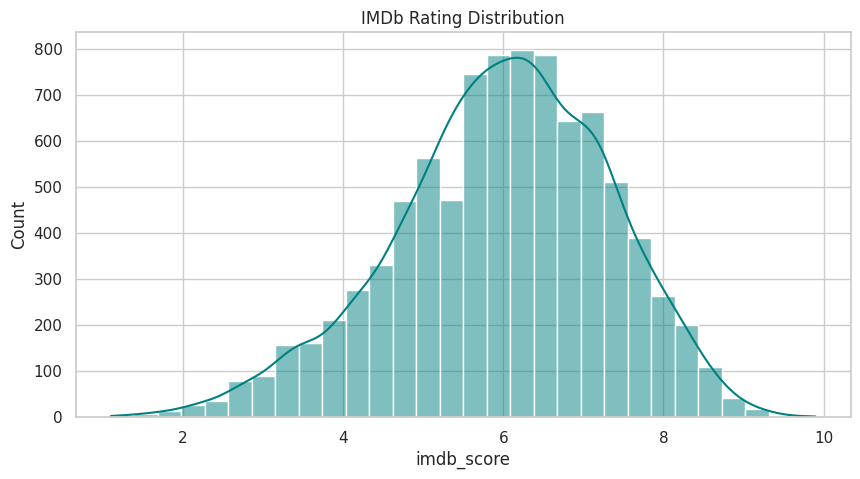

In [ ]:
# Vis 3: IMDb Rating Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=unique_titles.dropna(subset=['imdb_score']), x='imdb_score', kde=True, bins=30, color='teal')
plt.title('IMDb Rating Distribution')
plt.show()

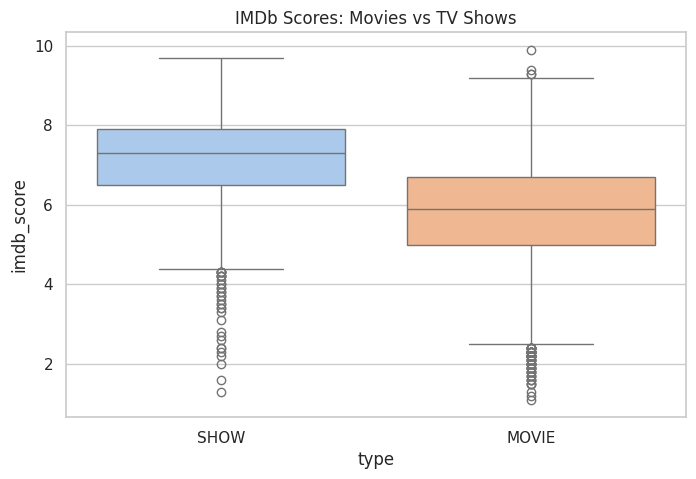

In [ ]:
# Vis 4: IMDb Ratings by Content Type
plt.figure(figsize=(8, 5))
sns.boxplot(data=unique_titles.dropna(subset=['imdb_score']), x='type', y='imdb_score', palette='pastel')
plt.title('IMDb Scores: Movies vs TV Shows')
plt.show()

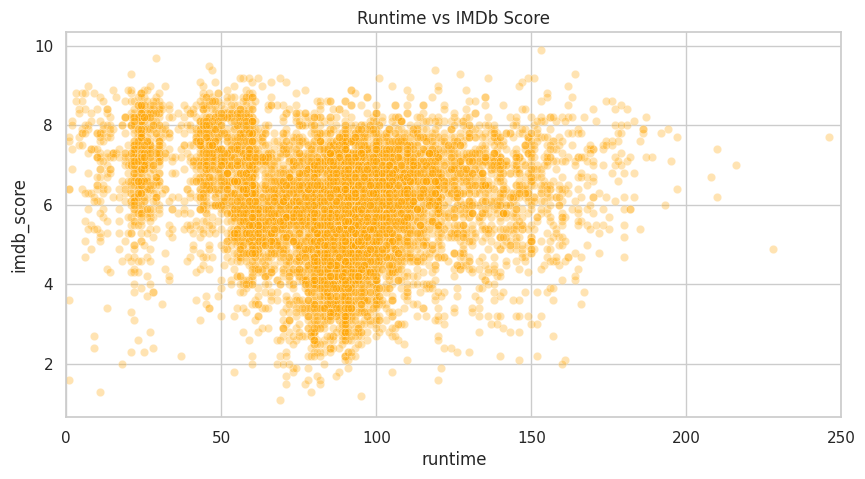

In [ ]:
# Vis 5: Runtime vs IMDb Score
plt.figure(figsize=(10, 5))
sns.scatterplot(data=unique_titles.dropna(subset=['imdb_score', 'runtime']), x='runtime', y='imdb_score', alpha=0.3, color='orange')
plt.title('Runtime vs IMDb Score')
plt.xlim(0, 250)
plt.show()

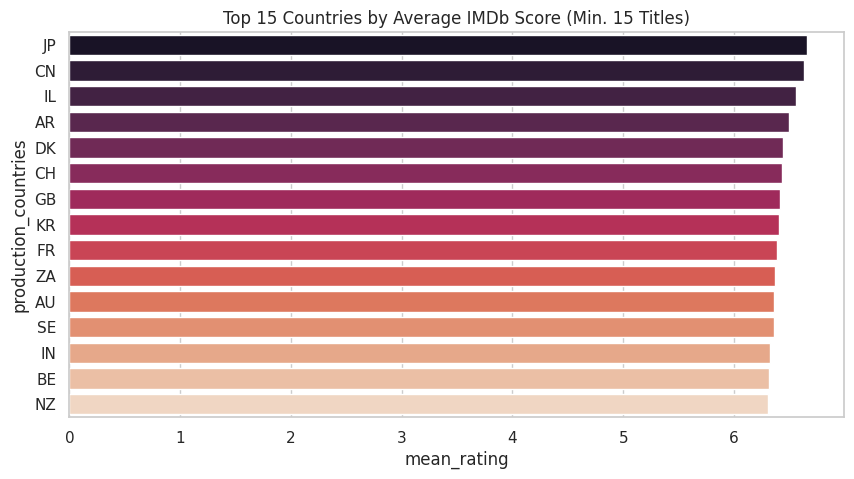

In [ ]:
# Vis 6: Country vs Average IMDb Rating
country_ratings = countries_exploded.groupby('production_countries').agg(mean_rating=('imdb_score', 'mean'), count=('id', 'count')).reset_index()
country_ratings_filtered = country_ratings[country_ratings['count'] >= 15].sort_values(by='mean_rating', ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(data=country_ratings_filtered, x='mean_rating', y='production_countries', palette='rocket')
plt.title('Top 15 Countries by Average IMDb Score (Min. 15 Titles)')
plt.show()

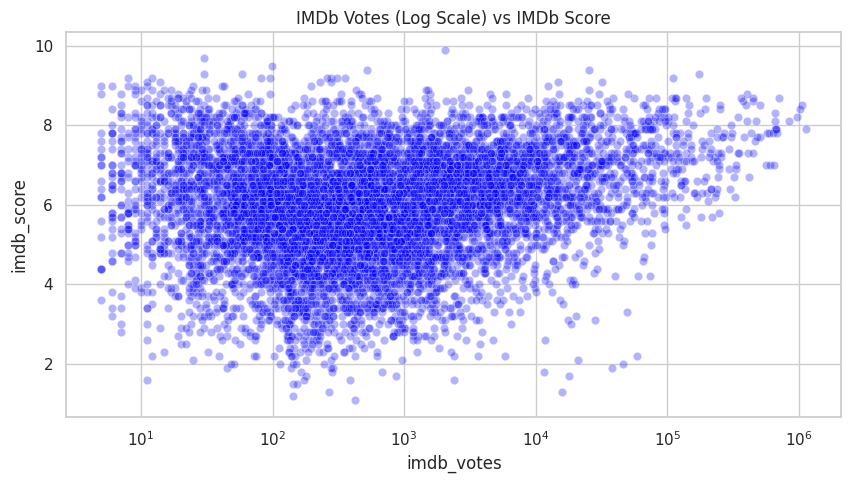

In [ ]:
# Vis 7: IMDb Votes vs IMDb Score
plt.figure(figsize=(10, 5))
sns.scatterplot(data=unique_titles.dropna(subset=['imdb_score', 'imdb_votes']), x='imdb_votes', y='imdb_score', alpha=0.3, color='blue')
plt.xscale('log')
plt.title('IMDb Votes (Log Scale) vs IMDb Score')
plt.show()

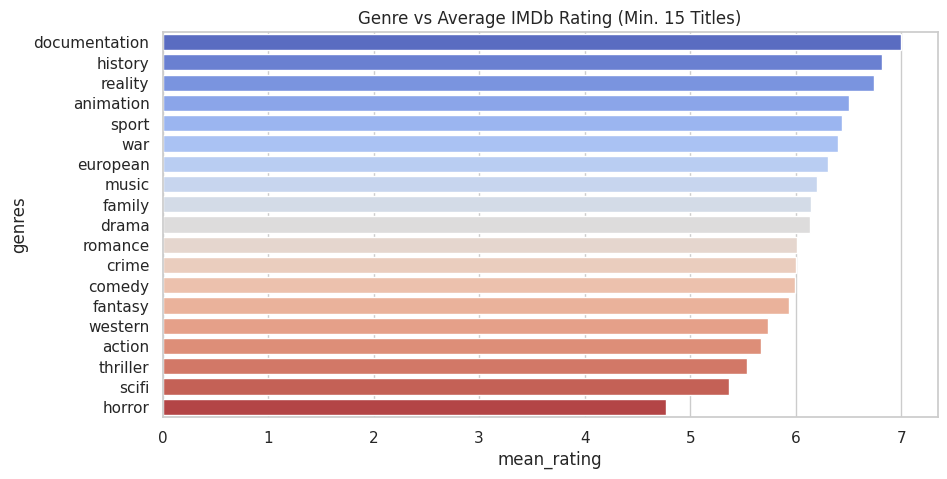

In [ ]:
# Vis 8: Genre vs Average IMDb Rating
genre_ratings = genres_exploded.groupby('genres').agg(mean_rating=('imdb_score', 'mean'), count=('id', 'count')).reset_index()
genre_ratings_filtered = genre_ratings[genre_ratings['count'] >= 15].sort_values(by='mean_rating', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=genre_ratings_filtered, x='mean_rating', y='genres', palette='coolwarm')
plt.title('Genre vs Average IMDb Rating (Min. 15 Titles)')
plt.show()

Machine Learning: Logistic Regression Model

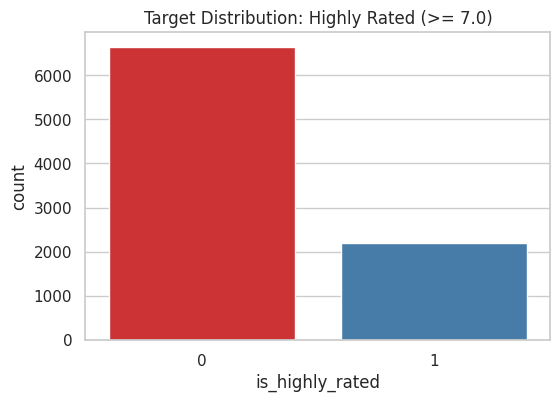

is_highly_rated
0    0.751186
1    0.248814
Name: proportion, dtype: float64


In [ ]:
# Drop samples missing imdb_score to avoid data leakage or invalid target labels
ml_df = unique_titles.dropna(subset=['imdb_score']).copy()

# Create target
ml_df['is_highly_rated'] = (ml_df['imdb_score'] >= 7.0).astype(int)

# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=ml_df, x='is_highly_rated', palette='Set1')
plt.title('Target Distribution: Highly Rated (>= 7.0)')
plt.show()

print(ml_df['is_highly_rated'].value_counts(normalize=True))

In [ ]:
# Feature Selection
features = ['type', 'release_year', 'runtime', 'seasons']
X = ml_df[features]
y = ml_df['is_highly_rated']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Pipelines & Preprocessing
num_features = ['release_year', 'runtime', 'seasons']
cat_features = ['type']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

# Build Models
model_normal = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

model_balanced = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'))
])

model_normal.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)

print("Both Logistic Regression models trained successfully!")

Both Logistic Regression models trained successfully!


 Model Evaluations

--- NORMAL LOGISTIC REGRESSION ---
              precision    recall  f1-score   support

           0       0.81      0.92      0.86      1330
           1       0.59      0.34      0.43       440

    accuracy                           0.78      1770
   macro avg       0.70      0.63      0.65      1770
weighted avg       0.75      0.78      0.75      1770


--- BALANCED LOGISTIC REGRESSION ---
              precision    recall  f1-score   support

           0       0.82      0.83      0.83      1330
           1       0.47      0.46      0.46       440

    accuracy                           0.74      1770
   macro avg       0.65      0.64      0.64      1770
weighted avg       0.73      0.74      0.74      1770



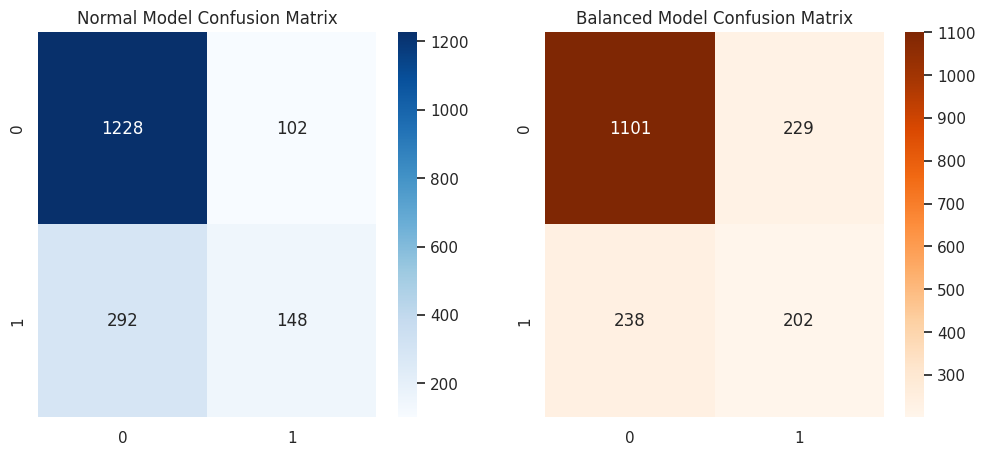

In [ ]:
y_pred_norm = model_normal.predict(X_test)
y_pred_bal = model_balanced.predict(X_test)

print("--- NORMAL LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_norm))

print("\n--- BALANCED LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_bal))

# Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_norm), annot=True, fmt='d', ax=axes[0], cmap='Blues')
axes[0].set_title('Normal Model Confusion Matrix')

sns.heatmap(confusion_matrix(y_test, y_pred_bal), annot=True, fmt='d', ax=axes[1], cmap='Oranges')
axes[1].set_title('Balanced Model Confusion Matrix')
plt.show()